## Importing Relevant Libraries

In [5]:
import os 
import pathlib 
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

## Setting Directories/Lodaing Datset


In [6]:
train_dir = pathlib.Path('C:\\Users\\Kiplagat\\Downloads\\Lux Notes\\Wheat_plant_diseases_classification\\Data\\train')
valid_dir = pathlib.Path('C:\\Users\\Kiplagat\\Downloads\\Lux Notes\\Wheat_plant_diseases_classification\\Data\\valid')
test_dir = pathlib.Path('C:\\Users\\Kiplagat\\Downloads\\Lux Notes\\Wheat_plant_diseases_classification\\Data\\test')

## Exploring the data

In [7]:
image_extension = ('.jpg','.jpeg','.png','.bmp','.gif')

def count_images(folder):
    counts = {}
    for class_dir in sorted(p for p in folder.iterdir() if p.is_dir()):
        counts[class_dir.name] = sum(1 for f in class_dir.iterdir()if f.suffix.lower() in image_extension)
    return counts

In [8]:
train_counts = count_images(train_dir)
print(f'number of classes: {len(train_counts)}')

number of classes: 15


In [9]:
print(f'training images: {sum(train_counts.values())}')

training images: 13104


In [10]:
print(f'Validation images: {sum(count_images(valid_dir).values())}')

Validation images: 300


## Plotting the various images

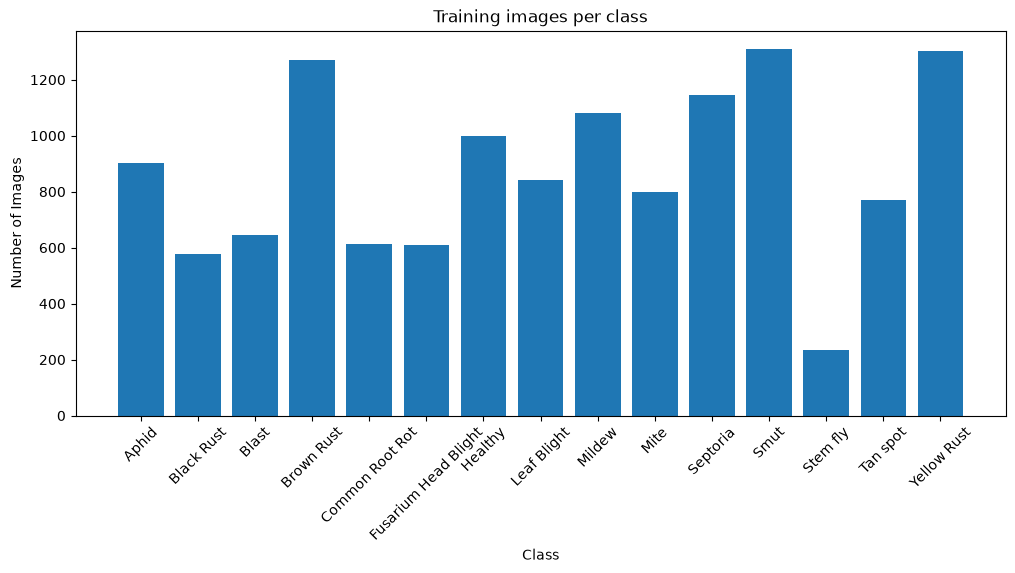

In [11]:
plt.figure(figsize=(12,5))
plt.bar(train_counts.keys(),train_counts.values())
plt.ylabel('Number of Images')
plt.xlabel('Class')
plt.title('Training images per class')
plt.xticks(rotation = 45)
plt.show()

## Loading Data

In [12]:
batch_size = 64
image_height = 256
image_width = 256

train_ds = tf.keras.utils.image_dataset_from_directory(
                                                        train_dir,
                                                        seed = 123,
                                                        image_size = (image_height,image_width),
                                                        shuffle = True
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
                                                        valid_dir,
                                                        seed = 123,
                                                        image_size = (image_height,image_width),
                                                        shuffle = True
)


Found 13104 files belonging to 15 classes.
Found 300 files belonging to 15 classes.


### Visualizing

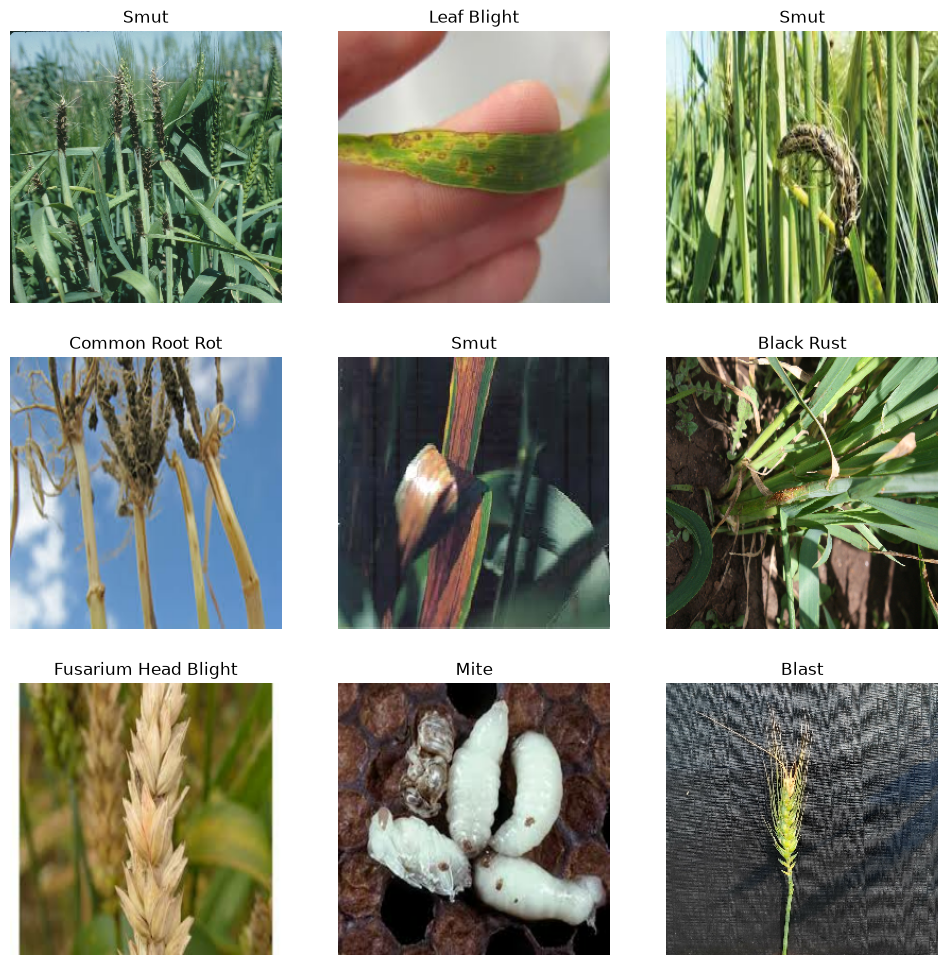

In [13]:
class_names = train_ds.class_names

plt.figure(figsize=(12,12))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')

plt.show()


In [14]:
print(class_names)

['Aphid', 'Black Rust', 'Blast', 'Brown Rust', 'Common Root Rot', 'Fusarium Head Blight', 'Healthy', 'Leaf Blight', 'Mildew', 'Mite', 'Septoria', 'Smut', 'Stem fly', 'Tan spot', 'Yellow Rust']


## Checking the shape of the dataset

In [15]:
for image_batch, labels_batch in train_ds:
    print('image_batch.shape',image_batch.shape)
    print('labels_batch.shape',labels_batch.shape)
    break


image_batch.shape (32, 256, 256, 3)
labels_batch.shape (32,)


## Creating a basic model

In [17]:
model = Sequential(
                [layers.Input(shape = (256,256,3)),
                layers.Rescaling(1.0 / 255),
                layers.Conv2D(16,3,activation = 'relu',padding ='same'),
                layers.MaxPooling2D(),
                layers.Conv2D(16,3,activation = 'relu',padding ='same'),
                layers.MaxPooling2D(),
                layers.Conv2D(16,3,activation = 'relu',padding ='same'),
                layers.MaxPooling2D(),
                layers.Flatten(),
                layers.Dense(128,activation = 'relu'),
                layers.Dense(128,activation = 'relu'),
                layers.Dense(15,activation = 'softmax')]
)

## Compling the model

In [18]:
model.compile(optimizer = 'adam',loss ='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,815 (8.09 MB)

 Trainable params: 2,120,815 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

## Training the model

In [19]:
history = model.fit(train_ds,validation_data = valid_ds,epochs = 50)

Epoch 1/50


c:\Users\Kiplagat\Downloads\Lux Notes\Wheat_plant_diseases_classification\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


410/410 ━━━━━━━━━━━━━━━━━━━━ 1342s 3s/step - accuracy: 0.3909 - loss: 1.9373 - val_accuracy: 0.3400 - val_loss: 2.1931
Epoch 2/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 931s 2s/step - accuracy: 0.5823 - loss: 1.3115 - val_accuracy: 0.5500 - val_loss: 1.5364
Epoch 3/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 2730s 7s/step - accuracy: 0.7100 - loss: 0.8911 - val_accuracy: 0.7167 - val_loss: 1.0912
Epoch 4/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 569s 1s/step - accuracy: 0.8004 - loss: 0.6049 - val_accuracy: 0.8067 - val_loss: 1.0651
Epoch 5/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 485s 1s/step - accuracy: 0.8707 - loss: 0.3844 - val_accuracy: 0.8367 - val_loss: 1.0290
Epoch 6/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 494s 1s/step - accuracy: 0.9060 - loss: 0.2815 - val_accuracy: 0.8767 - val_loss: 1.1788
Epoch 7/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 476s 1s/step - accuracy: 0.9277 - loss: 0.2144 - val_accuracy: 0.8567 - val_loss: 1.0579
Epoch 8/50
410/410 ━━━━━━━━━━━━━━━━━━━━ 490s 1s/step - accuracy: 0.9383 - loss: 0.1801 - val_accuracy: 0.7


KeyboardInterrupt

